<a href="https://colab.research.google.com/github/Aurora-DS-1728821/AnalyticsEngineeringPracticeWork/blob/main/2_03_practice_bike_hire_student.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

![](https://drive.google.com/uc?export=view&id=17M9oGaOj4KdKiDDH3oTibxJ9qBTSjp6n)

# 2.03 Practice session
## Bike-hire trips

## How this practice works

This is a **short rehearsal** of the timed test. You do not need to finish or get the "right" answer. The aim is to practise the way of working.

- You have about **45 minutes**. Work individually.
- You may use **any AI tool** (for example Gemini in Colab). We are **not marking** anything today. In the real test, the quality of AI-generated code will not matter. What matters is the control youDshow.
- Write in markdown cells as you go: your thinking, **each prompt you send (paste it as you send it)**, and the checks you make.
- Unfinished work is fine. Say what you did not get to.
- At the end, download the Notebook (using File > Download > Download .ipynb). Once it has completed please zip the file up. This is the artefact you would submit for the in-class test.
- You can also save a copy to your GitHub using the instructions from my.wbs (1b asychronous tasks).

**Suggested timing**

| Minutes | Focus |
| --- | --- |
| 0 to 10 | Look at the tables and note what you find |
| 10 to 25 | Clean and prepare the data |
| 25 to 38 | Join and aggregate to answer the question |
| 38 to 45 | Check your answer and write up |

At the end, use **Runtime, then Restart session and run all** and note anything that fails.


## The data

A fictional bike-hire scheme: three tables covering trips taken in March 2025.

| Table | What it holds |
| --- | --- |
| `trips` | One record per trip: bike, start and end station, start time, duration and user type |
| `bikes` | The bikes, with type and purchase year |
| `stations` | The docking stations, with zone and capacity |

**How they connect:** `trips.bike_id` to `bikes.bike_id`, and `trips.start_station_id` (and `end_station_id`) to `stations.station_id`.

Check the real column names in the next cell before you write anything.


In [ ]:
# ---- Setup: run this cell first ----
!pip install -q duckdb

import glob
import os

import duckdb
import pandas as pd

DATA_URL = "https://github.com/MJMortensonWarwick/adminaeaiv/releases/download/dbsession/bike-hire-practice.zip"

DATA_DIR = "/content/bikes"
# Download only if no CSV files are there yet. The CSVs may sit inside a folder
# within the zip; the search below looks in sub-folders too.
if DATA_URL and not glob.glob(os.path.join(DATA_DIR, "**", "*.csv"), recursive=True):
    import urllib.request
    import zipfile
    os.makedirs(DATA_DIR, exist_ok=True)
    urllib.request.urlretrieve(DATA_URL, "/content/bikes.zip")
    zipfile.ZipFile("/content/bikes.zip").extractall(DATA_DIR)

FILES = {"trips": "trips.csv", "bikes": "bikes.csv", "stations": "stations.csv"}

tables, missing = {}, []
for name, filename in FILES.items():
    found = glob.glob(os.path.join(DATA_DIR, "**", filename), recursive=True)
    if found:
        tables[name] = pd.read_csv(found[0])
    else:
        missing.append(filename)

if missing:
    found_csvs = sorted(os.path.basename(f) for f in glob.glob(os.path.join(DATA_DIR, "**", "*.csv"), recursive=True))
    raise FileNotFoundError(
        f"Missing files: {missing}. CSV files found under {DATA_DIR}: {found_csvs}. Ask for help."
    )

# Make every table available as a DuckDB table, so you can use SQL or pandas.
con = duckdb.connect()
for name, df in tables.items():
    con.register(name, df)


def q(sql):
    """Run SQL against the tables above and return a pandas DataFrame."""
    return con.sql(sql).df()


for name, df in tables.items():
    print(f"{name}: {df.shape[0]:,} rows, {df.shape[1]} columns")
    print("   ", list(df.columns))


trips: 612 rows, 7 columns
    ['trip_id', 'bike_id', 'start_station_id', 'end_station_id', 'start_time', 'duration_min', 'user_type']
bikes: 60 rows, 3 columns
    ['bike_id', 'bike_type', 'purchase_year']
stations: 12 rows, 4 columns
    ['station_id', 'station_name', 'zone', 'capacity']


## Examples: two ways to work with the tables

You can use SQL, pandas, or a mix of both. The next two cells show each. Run them and change them to see what happens. You do not have to use them in your answer.


In [ ]:
# Example 1: SQL
# q() runs SQL against any of the tables above and returns a pandas DataFrame.
from IPython.display import display

display(q("SELECT * FROM trips LIMIT 5"))

display(q("SELECT COUNT(*) AS n_rows, COUNT(DISTINCT trip_id) AS n_distinct_trips FROM trips"))

display(q("""
    SELECT t.trip_id, s.station_name
    FROM trips AS t
    JOIN stations AS s ON t.start_station_id = s.station_id
    LIMIT 5
"""))


,trip_id,bike_id,start_station_id,end_station_id,start_time,duration_min,user_type
0,T0001,B028,S05,S01,2025-03-01 05:52:00,21.0,Casual
1,T0002,B043,S12,S12,2025-03-01 06:31:00,27.0,CASUAL
2,T0003,B045,S11,S07,2025-03-01 07:06:00,18.0,Casual
3,T0004,B051,S04,S04,2025-03-01 07:06:00,34.0,Member
4,T0005,B049,S01,S09,2025-03-01 07:36:00,16.0,Member


,n_rows,n_distinct_trips
0,612,600


,trip_id,station_name
0,T0001,Park Road
1,T0002,Cathedral Close
2,T0003,Sports Centre
3,T0004,University Gate
4,T0005,Market Square


In [ ]:
# Example 2: pandas
# Each table is also a pandas DataFrame, stored in the dictionary `tables`.
from IPython.display import display

trips = tables["trips"]
display(trips.head())
print(trips.shape)
print(trips.dtypes)

joined = tables["trips"].merge(tables["stations"], left_on="start_station_id", right_on="station_id", how="inner")
display(joined[["trip_id", "station_name"]].head())

# You can mix the two: run SQL, then use pandas methods on the result
result = q("SELECT start_station_id FROM trips")
print(result["start_station_id"].nunique(), "different start stations in trips")


,trip_id,bike_id,start_station_id,end_station_id,start_time,duration_min,user_type
0,T0001,B028,S05,S01,2025-03-01 05:52:00,21.0,Casual
1,T0002,B043,S12,S12,2025-03-01 06:31:00,27.0,CASUAL
2,T0003,B045,S11,S07,2025-03-01 07:06:00,18.0,Casual
3,T0004,B051,S04,S04,2025-03-01 07:06:00,34.0,Member
4,T0005,B049,S01,S09,2025-03-01 07:36:00,16.0,Member


(612, 7)
trip_id              object
bike_id              object
start_station_id     object
end_station_id       object
start_time           object
duration_min        float64
user_type            object
dtype: object


,trip_id,station_name
0,T0001,Park Road
1,T0002,Cathedral Close
2,T0003,Sports Centre
3,T0004,University Gate
4,T0005,Market Square


12 different start stations in trips


## Your brief

**From:** the scheme manager

> We want to know whether electric bikes are used for longer trips than standard bikes, and whether that differs by zone. Please give us the **average trip duration by bike type and by the zone of the start station**.

![](https://drive.google.com/uc?export=view&id=1eH5Q3l4LnzwZ-XcT_kJDeHoKA2rufiOW)

**What your final table should look like**

One row per combination of bike type and zone, with the number of trips and the average duration in minutes. State what one row represents.

**Things to think about** (you do not have to solve all of them)

- Are there missing, duplicated or odd values in the tables you use? What will you do about each, and why?
- Do the bike types and dates look consistent?
- How will you check your final table is believable?


## 1. Look at the data

*What does one row of each table represent? Which columns will you use? What looks odd, missing or inconsistent? Write down what you find.*

In [ ]:
# Create the bikes table in pandas
bikes = tables["bikes"]

#Check the first few rows of the table
display(bikes.head())

#Check df shape and data types
print(bikes.shape)
print(bikes.dtypes)


,bike_id,bike_type,purchase_year
0,B001,Standard,2021
1,B002,Electric,2022
2,B003,electric,2024
3,B004,Standard,2021
4,B005,STANDARD,2022


(60, 3)
bike_id          object
bike_type        object
purchase_year     int64
dtype: object


In [ ]:
#Check the first few rows of the trips table
display(trips.head())

#Check df shape and data types
print(trips.shape)
print(trips.dtypes)

,trip_id,bike_id,start_station_id,end_station_id,start_time,duration_min,user_type
0,T0001,B028,S05,S01,2025-03-01 05:52:00,21.0,Casual
1,T0002,B043,S12,S12,2025-03-01 06:31:00,27.0,CASUAL
2,T0003,B045,S11,S07,2025-03-01 07:06:00,18.0,Casual
3,T0004,B051,S04,S04,2025-03-01 07:06:00,34.0,Member
4,T0005,B049,S01,S09,2025-03-01 07:36:00,16.0,Member


(612, 7)
trip_id              object
bike_id              object
start_station_id     object
end_station_id       object
start_time           object
duration_min        float64
user_type            object
dtype: object


In [ ]:
# Create the stations table in pandas
stations = tables["stations"]

#Check the first few rows of the table
display(stations.head())

#Check df shape and data types
print(stations.shape)
print(stations.dtypes)

,station_id,station_name,zone,capacity
0,S01,Market Square,Centre,29.0
1,S02,Railway Station,Centre,23.0
2,S03,Canal Basin,North,24.0
3,S04,University Gate,West,28.0
4,S05,Park Road,South,22.0


(12, 4)
station_id       object
station_name     object
zone             object
capacity        float64
dtype: object


## 2. Clean and prepare

*Decide what to do about each problem you found, say why, and do it. Short cells that you can re-run are better than one long cell.*

In [ ]:
# Trips table
# check for duplicates
print("There are:" ,trips.duplicated().sum(), "duplicates")

# check for missing values
print(trips.isnull().sum())

There are: 12 duplicates
trip_id              0
bike_id              0
start_station_id     0
end_station_id       0
start_time           0
duration_min        30
user_type            0
dtype: int64


In [ ]:
#Remove 30 missing values for duration
trips = trips.dropna(subset=['duration_min'])

#Check null values
print(trips.isnull().sum())

trip_id             0
bike_id             0
start_station_id    0
end_station_id      0
start_time          0
duration_min        0
user_type           0
dtype: int64


In [ ]:
#Standardise user_type and remove extra spaces
trips['user_type'] = trips['user_type'].str.strip()
trips['user_type'] = trips['user_type'].str.upper()


#Check unique values
print(trips['user_type'].unique())

['CASUAL' 'MEMBER']


/tmp/ipykernel_3101/2240390557.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trips['user_type'] = trips['user_type'].str.strip()
/tmp/ipykernel_3101/2240390557.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trips['user_type'] = trips['user_type'].str.upper()


In [ ]:
# Re-check duplicates
print("There are:" ,trips.duplicated().sum(), "duplicates")

#Remove the duplicates
trips = trips.drop_duplicates()

# Re-check duplicates
print("There are:" ,trips.duplicated().sum(), "duplicates")

There are: 12 duplicates
There are: 0 duplicates


In [ ]:
#Standardise start_time
trips['start_time'] = pd.to_datetime(trips['start_time'], format= "mixed", dayfirst=True)


print(trips.head())
#Check data type
print(trips['start_time'].dtypes)

  trip_id bike_id start_station_id end_station_id          start_time  \
0   T0001    B028              S05            S01 2025-03-01 05:52:00   
1   T0002    B043              S12            S12 2025-03-01 06:31:00   
2   T0003    B045              S11            S07 2025-03-01 07:06:00   
3   T0004    B051              S04            S04 2025-03-01 07:06:00   
4   T0005    B049              S01            S09 2025-03-01 07:36:00   

   duration_min user_type  
0          21.0    CASUAL  
1          27.0    CASUAL  
2          18.0    CASUAL  
3          34.0    MEMBER  
4          16.0    MEMBER  
datetime64[ns]


In [ ]:
#Stations table
# check for duplicates
print("There are:" ,stations.duplicated().sum(), "duplicates")
print(stations)

print(stations.shape)
# check for missing values
print(stations.isnull().sum())

There are: 0 duplicates
   station_id       station_name    zone  capacity
0         S01      Market Square  Centre      29.0
1         S02    Railway Station  Centre      23.0
2         S03        Canal Basin   North      24.0
3         S04    University Gate    West      28.0
4         S05          Park Road   South      22.0
5         S06     Library Corner  Centre      26.0
6         S07  Hospital Entrance    East      27.0
7         S08     Riverside Walk   South      14.0
8         S09      Old Town Hall  Centre       NaN
9         S10        Retail Park   North      16.0
10        S11      Sports Centre    West      15.0
11        S12    Cathedral Close  Centre      28.0
(12, 4)
station_id      0
station_name    0
zone            0
capacity        1
dtype: int64


In [ ]:
#Bikes table
# check for duplicates
print("There are:" ,bikes.duplicated().sum(), "duplicates")
print(bikes.shape)

print(bikes.head())
# check for missing values
print(bikes.isnull().sum())

There are: 0 duplicates
(60, 3)
  bike_id  bike_type  purchase_year
0    B001   Standard           2021
1    B002  Electric            2022
2    B003   electric           2024
3    B004   Standard           2021
4    B005   STANDARD           2022
bike_id          0
bike_type        0
purchase_year    0
dtype: int64


In [ ]:
#Standardise bike_type
bikes['bike_type'] = bikes['bike_type'].str.strip()
bikes['bike_type'] = bikes['bike_type'].str.upper()

#Change e-bike to electric
bikes['bike_type'] = bikes['bike_type'].replace('E-BIKE', 'ELECTRIC')

#Check unique values
print(bikes['bike_type'].unique())


['STANDARD' 'ELECTRIC']


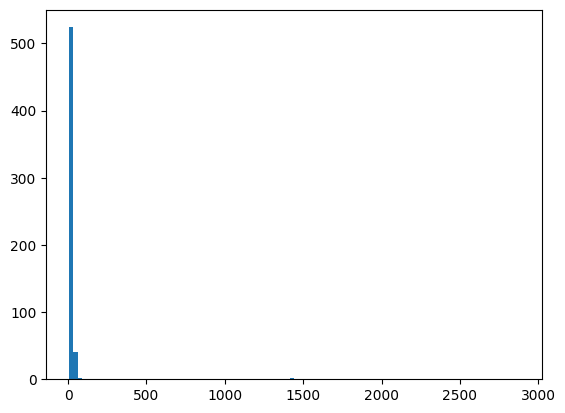

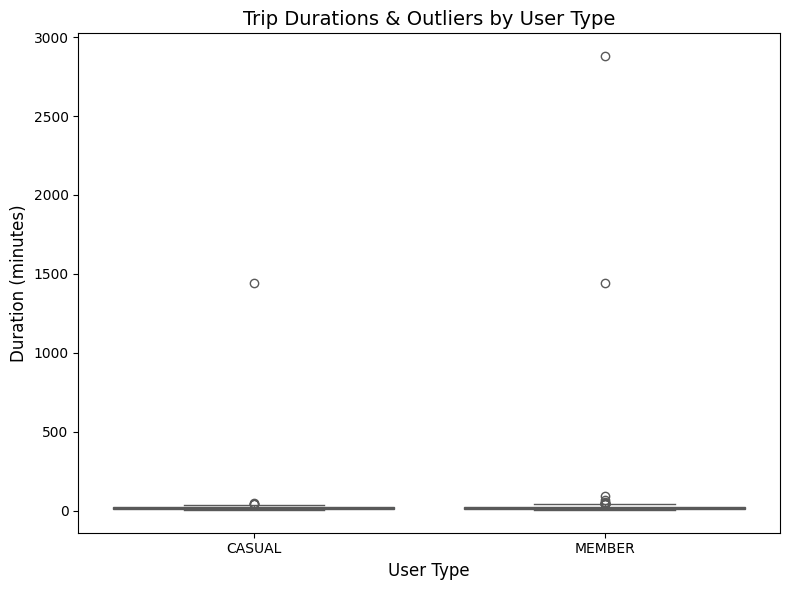

In [ ]:
#Plot the data to check for outliers in the trips duration
import matplotlib.pyplot as plt
import seaborn as sns


plt.hist(trips['duration_min'], bins=100)
plt.show()

#Show a boxplot by user type
plt.figure(figsize=(8, 6))

sns.boxplot(data=trips, x='user_type', y='duration_min', palette='Set2', hue='user_type', legend=False)
plt.title('Trip Durations & Outliers by User Type', fontsize=14)
plt.xlabel('User Type', fontsize=12)
plt.ylabel('Duration (minutes)', fontsize=12)

plt.tight_layout()
plt.show()

In [ ]:
# 1. Identify and display the extreme outliers (trips over 10 hours / 600 minutes)
outliers = trips[trips['duration_min'] > 600]
print("=== OUTLIER TRIPS IDENTIFIED ===")
display(outliers)

# 2. Filter them out from our main dataset
trips_cleaned = trips[trips['duration_min'] <= 600]

# 3. Update the global variables and tables dictionary to use the cleaned dataset
trips = trips_cleaned
tables["trips"] = trips

print(f"\nOriginal trips count: {len(trips_cleaned) + len(outliers)}")
print(f"Trips remaining after removing outliers: {len(trips)}")

=== OUTLIER TRIPS IDENTIFIED ===


,trip_id,bike_id,start_station_id,end_station_id,start_time,duration_min,user_type
80,T0081,B010,S12,S11,2025-03-04 21:57:00,2880.0,MEMBER
143,T0143,B020,S09,S10,2025-03-08 12:23:00,1440.0,CASUAL
287,T0284,B046,S08,S03,2025-03-15 20:25:00,1440.0,MEMBER



Original trips count: 570
Trips remaining after removing outliers: 567


## 3. Join and aggregate

*Join the tables and calculate the answer. Note how many rows you expect after each join, then check.*

In [ ]:
#Join the Bikes and the Trips tables by bike_id
bike_and_trip = trips.merge(bikes, left_on="bike_id", right_on="bike_id", how="inner")

#Join the new table to the stations table by start_station_id = station_id
bike_trip_station = bike_and_trip.merge(stations, left_on="start_station_id", right_on="station_id", how="inner")

#Check the result
bike_trip_station.head()



,trip_id,bike_id,start_station_id,end_station_id,start_time,duration_min,user_type,bike_type,purchase_year,station_id,station_name,zone,capacity
0,T0001,B028,S05,S01,2025-03-01 05:52:00,21.0,CASUAL,STANDARD,2021,S05,Park Road,South,22.0
1,T0002,B043,S12,S12,2025-03-01 06:31:00,27.0,CASUAL,STANDARD,2021,S12,Cathedral Close,Centre,28.0
2,T0003,B045,S11,S07,2025-03-01 07:06:00,18.0,CASUAL,STANDARD,2024,S11,Sports Centre,West,15.0
3,T0004,B051,S04,S04,2025-03-01 07:06:00,34.0,MEMBER,ELECTRIC,2024,S04,University Gate,West,28.0
4,T0005,B049,S01,S09,2025-03-01 07:36:00,16.0,MEMBER,STANDARD,2023,S01,Market Square,Centre,29.0


## 4. Check

*How do you know the answer is right? Compare a count, spot check a few records, or recalculate one number a different way. What did you find?*

## 5. Prompts and AI notes

*Paste each prompt as you sent it. Note what you accepted, changed or rejected and why.*

## 6. What I could not verify

*What remains unchecked? What would you do next?*